# Pickup and delivery

A city courier collects parcels from one customer and carries them to another. Each **request** is
a pair of stops: the same van must make both, the pickup must come first, and the van can never
carry more than fits at one moment. The question is **which van takes which request, and in what
order its stops run**.

That pairing is the difference from plain vehicle routing, where a stop can move anywhere on its
own. Here a stop drags its partner along.

In this notebook you will:

1. describe a courier day as Python objects,
2. solve it and draw the routes on a map and the load inside each van over time,
3. check the result yourself, without trusting the solver's score,
4. add a rule that serves the longest-waiting orders sooner,
5. tighten the delivery deadlines and see what the solver gives up,
6. pin the stops a van has already made, add a late request, and keep searching.

Requires Python 3.11+: `pip install optimaru matplotlib`

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D

from optimaru import pickup_delivery as pdp
from optimaru.pickup_delivery import constraints as rules
from optimaru.pickup_delivery.models import (
    DeliveryModel, PdpInput, PdpRequest, StopModel, VehicleModel, solve_request, with_initial_solution,
)

COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, MUTED = "#52514e", "#898781"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "xtick.color": MUTED, "ytick.color": MUTED,
    "grid.color": "#e1e0d9", "grid.linewidth": 0.8, "legend.frameon": False, "font.size": 10,
})

## 1. Describe the courier day

This notebook uses the pydantic models in `optimaru.pickup_delivery.models`. They hold one request as
one object, and they are the simplest way to set pinned stops and order times. All times are
**integer seconds from the start of the day**, so `8 * 3600` is 08:00.

| Object | What it holds |
| --- | --- |
| `StopModel` | one stop: location, time window, service duration |
| `DeliveryModel` | one request: its demand, a pickup stop, a dropoff stop |
| `VehicleModel` | one van: capacity, start location, departure time, optional route limits |
| `PdpInput` | the vehicles and the requests, with an optional driving-time matrix |

Here is a fictional day: 24 requests around a depot, served by 3 vans. Each request has a booking
hour. Its pickup can start from then, and its dropoff must finish before a deadline.

Two defaults are worth knowing. Routes are open: a van ends the day at its last stop unless
`return_to_depot=True`. And `VehicleModel` caps a van at 20 stops, where a request counts as two.
This notebook sets `max_stops=0` to lift that cap, so that capacity and time decide the routes.

In [2]:
HOUR = 3600
REQUESTS = 24
DEPOT = (35.16, 129.06)

rng = np.random.default_rng(11)
orders = []
for i in range(REQUESTS):
    pickup = (DEPOT[0] + rng.normal(0, 0.05), DEPOT[1] + rng.normal(0, 0.07))
    dropoff = (DEPOT[0] + rng.normal(0, 0.05), DEPOT[1] + rng.normal(0, 0.07))
    booked = 9 + int(rng.integers(0, 5))
    orders.append(dict(id=f"R{i:02d}", demand=int(rng.integers(1, 6)), pickup=pickup, dropoff=dropoff, booked=booked))


def make_input(vehicle_count=3, capacity=8, deadline_hours=3.0):
    """A fresh problem. `deadline_hours` runs from the booking hour to the end of the dropoff."""
    deliveries = []
    for order in orders:
        opens = order["booked"] * HOUR
        deliveries.append(DeliveryModel(
            id=order["id"],
            demand=order["demand"],
            pickup=StopModel(
                id=f"{order['id']}-P", location=order["pickup"], min_start_time=opens,
                max_end_time=opens + int(min(2, deadline_hours) * HOUR), service_duration=5 * 60,
            ),
            dropoff=StopModel(
                id=f"{order['id']}-D", location=order["dropoff"], min_start_time=opens,
                max_end_time=opens + int(deadline_hours * HOUR), service_duration=5 * 60,
            ),
        ))
    vehicles = [
        VehicleModel(id=f"Van {k + 1}", capacity=capacity, home=DEPOT, departure_time=8 * HOUR, max_stops=0)
        for k in range(vehicle_count)
    ]
    return PdpInput(vehicles=vehicles, deliveries=deliveries)


problem = make_input()
print(f"{len(problem.deliveries)} requests, {len(problem.vehicles)} vans")
print(f"total demand {sum(d.demand for d in problem.deliveries)}, "
      f"van capacity {problem.vehicles[0].capacity} at any one moment")

24 requests, 3 vans
total demand 67, van capacity 8 at any one moment


Total demand is well above what one van holds at once, and that is fine: capacity is a running peak,
not a route total. Load rises at a pickup and falls at the matching dropoff.

Without a `driving_seconds` matrix the plan computes a great-circle estimate, which is what this
notebook uses. Pass your own matrix from a road network if you have one.

Each gray line below is one request. The solver has to chain these pairs into routes.

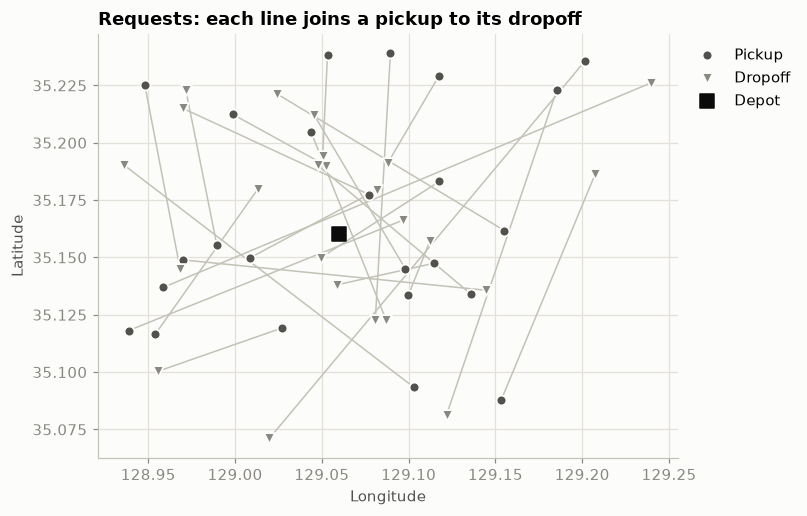

In [3]:
fig, ax = plt.subplots(figsize=(6.8, 5))
for order in orders:
    ax.plot([order["pickup"][1], order["dropoff"][1]], [order["pickup"][0], order["dropoff"][0]],
            color="#c3c2b7", linewidth=1, zorder=1)
ax.scatter([o["pickup"][1] for o in orders], [o["pickup"][0] for o in orders], s=42, color=INK,
           edgecolor="#fcfcfb", linewidth=1.2, label="Pickup", zorder=2)
ax.scatter([o["dropoff"][1] for o in orders], [o["dropoff"][0] for o in orders], s=50, marker="v", color=MUTED,
           edgecolor="#fcfcfb", linewidth=1.2, label="Dropoff", zorder=2)
ax.scatter(DEPOT[1], DEPOT[0], marker="s", s=90, color="#0b0b0b", label="Depot", zorder=3)
ax.set(title="Requests: each line joins a pickup to its dropoff", xlabel="Longitude", ylabel="Latitude")
ax.grid(True)
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

## 2. Solve it

`solve_request` takes a `PdpRequest`, which holds the problem, the time limit and the seed, and
returns a `PdpSolution`. The score has three levels, compared in order:

- **hard**: capacity excess, time-window lateness, and the pairing rules (a request is routed whole,
  on one van, pickup first). `0` means the plan is feasible.
- **medium**: minus the service minutes of requests left off every route
- **soft**: minus the total driving seconds

In [4]:
request = PdpRequest(timelimit=5, random_seed=42, model_input=problem)
solution = solve_request(request)

print("feasible:", solution.feasible)
print("score   :", solution.score)
print(f"driving : {solution.total_driving_seconds / HOUR:.1f} hours")
print("left out:", solution.unassigned)
for van, route in solution.routes.items():
    print(f"{van}: {' '.join(stop.stop_id for stop in route)}")

feasible: True
score   : 0hard/0medium/-19449soft
driving : 5.4 hours
left out: []
Van 1: R22-P R22-D R18-P R15-P R15-D R18-D
Van 2: R21-P R23-P R09-P R09-D R14-P R21-D R00-P R23-D R19-P R14-D R19-D R01-P R07-P R01-D R03-P R02-P R00-D R13-P R07-D R02-D R13-D R03-D
Van 3: R20-P R20-D R10-P R10-D R08-P R06-P R08-D R17-P R06-D R11-P R12-P R12-D R05-P R05-D R04-P R17-D R16-P R04-D R16-D R11-D


### The routes on a map

Circles are pickups and triangles are dropoffs, colored by van. Each route starts at the depot and
ends at its last dropoff.

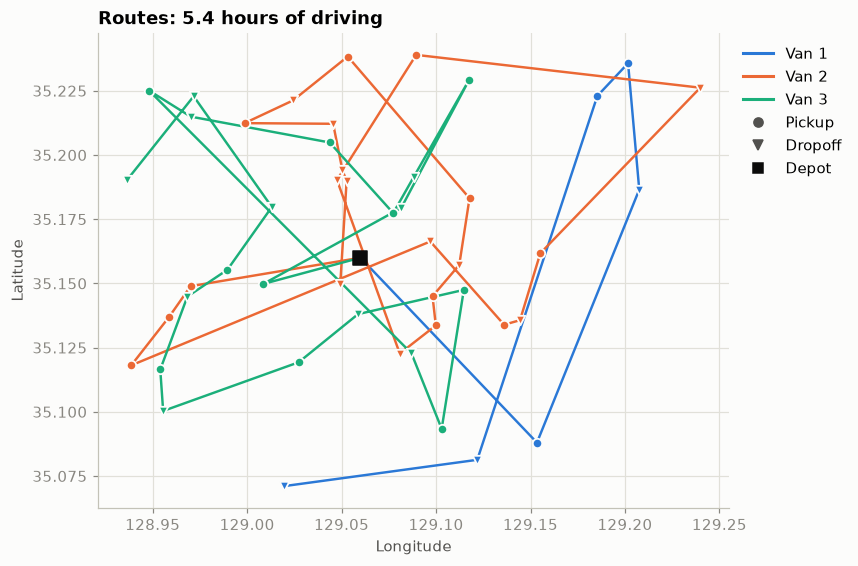

In [5]:
def coordinates(model_input):
    """Every stop id with its (latitude, longitude)."""
    return {
        stop.id: stop.location
        for delivery in model_input.deliveries
        for stop in (delivery.pickup, delivery.dropoff)
    }


def draw_routes(ax, model_input, solution):
    where = coordinates(model_input)
    for k, vehicle in enumerate(model_input.vehicles):
        route = solution.routes[vehicle.id]
        if route:
            points = [vehicle.home, *(where[stop.stop_id] for stop in route)]
            ax.plot([p[1] for p in points], [p[0] for p in points], color=COLORS[k], linewidth=1.6,
                    solid_capstyle="round", zorder=1)
            for pickup, marker in ((True, "o"), (False, "v")):
                stops = [where[stop.stop_id] for stop in route if stop.pickup is pickup]
                ax.scatter([p[1] for p in stops], [p[0] for p in stops], s=38, marker=marker, color=COLORS[k],
                           edgecolor="#fcfcfb", linewidth=1.2, zorder=2)
    for delivery in model_input.deliveries:
        if delivery.id in solution.unassigned:
            for stop in (delivery.pickup, delivery.dropoff):
                ax.scatter(stop.location[1], stop.location[0], marker="x", s=55, color="#0b0b0b", zorder=3)
    ax.scatter(DEPOT[1], DEPOT[0], marker="s", s=90, color="#0b0b0b", zorder=3)
    ax.set(xlabel="Longitude", ylabel="Latitude")
    ax.grid(True)


def route_legend(ax, model_input, extra=()):
    handles = [Line2D([], [], color=COLORS[k], linewidth=2, label=v.id) for k, v in enumerate(model_input.vehicles)]
    handles += [
        Line2D([], [], linestyle="", marker="o", color=INK, label="Pickup"),
        Line2D([], [], linestyle="", marker="v", color=INK, label="Dropoff"),
        Line2D([], [], linestyle="", marker="s", color="#0b0b0b", label="Depot"),
        *extra,
    ]
    ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1, 1))


fig, ax = plt.subplots(figsize=(7.4, 5.6))
draw_routes(ax, problem, solution)
ax.set_title(f"Routes: {solution.total_driving_seconds / HOUR:.1f} hours of driving")
route_legend(ax, problem)
plt.show()

### The load inside each van

A map cannot show what is on board. Here the load steps up at each pickup and down at each dropoff,
and the black line is the capacity. A van can move far more than its capacity over a day, as long as
the line stays under the limit.

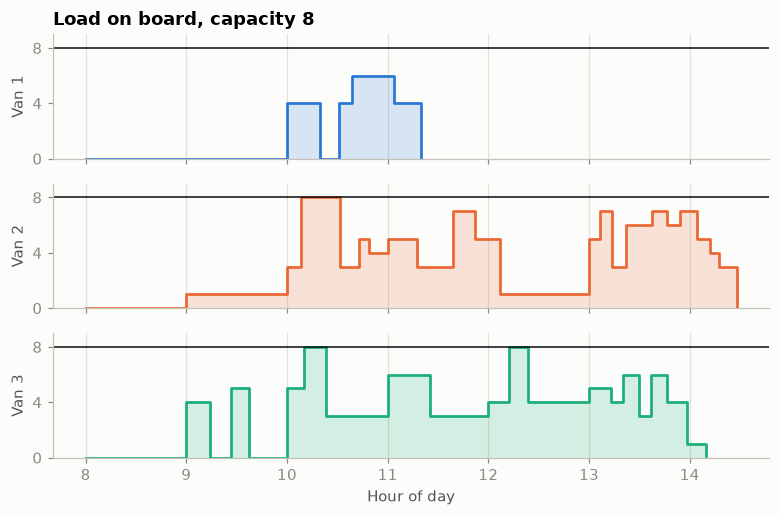

In [6]:
def load_steps(model_input, route):
    """(hour, load) after each stop, walking one route from its arrival times."""
    deliveries = {d.id: d for d in model_input.deliveries}
    stops = {s.id: s for d in model_input.deliveries for s in (d.pickup, d.dropoff)}
    hours, loads, load = [8.0], [0], 0
    for stop in route:
        load += deliveries[stop.delivery_id].demand * (1 if stop.pickup else -1)
        hours.append(max(stop.arrival_time, stops[stop.stop_id].min_start_time) / HOUR)
        loads.append(load)
    return hours, loads


fig, axes = plt.subplots(3, 1, figsize=(8.4, 5), sharex=True, sharey=True)
for k, (ax, vehicle) in enumerate(zip(axes, problem.vehicles)):
    hours, loads = load_steps(problem, solution.routes[vehicle.id])
    ax.step(hours, loads, where="post", color=COLORS[k], linewidth=1.8)
    ax.fill_between(hours, loads, step="post", color=COLORS[k], alpha=0.18, linewidth=0)
    ax.axhline(vehicle.capacity, color="#0b0b0b", linewidth=1)
    ax.set_ylabel(vehicle.id)
    ax.set_ylim(0, vehicle.capacity + 1)
    ax.set_yticks([0, vehicle.capacity // 2, vehicle.capacity])
    ax.grid(True, axis="x")
axes[0].set_title(f"Load on board, capacity {problem.vehicles[0].capacity}")
axes[-1].set_xlabel("Hour of day")
plt.show()

## 3. Check the result yourself

The solution reports each stop's arrival time, so it can be verified from the output alone. This
recomputes the hard rules with no solver code: every request served once, pickup first on one van,
load within capacity, and service finished inside the window.

A van that arrives early waits for the window to open, so service starts at the later of the arrival
and `min_start_time`.

In [7]:
deliveries = {d.id: d for d in problem.deliveries}
stops = {s.id: s for d in problem.deliveries for s in (d.pickup, d.dropoff)}

seen, wrong_order, split, late, overloaded = [], [], [], [], []
for vehicle in problem.vehicles:
    route = solution.routes[vehicle.id]
    order = [stop.stop_id for stop in route]
    seen += order
    load = 0
    for stop in route:
        load += deliveries[stop.delivery_id].demand * (1 if stop.pickup else -1)
        overloaded += [vehicle.id] if load > vehicle.capacity else []
        facts = stops[stop.stop_id]
        if max(stop.arrival_time, facts.min_start_time) + facts.service_duration > facts.max_end_time:
            late.append(stop.stop_id)
        delivery = deliveries[stop.delivery_id]
        if delivery.pickup.id not in order or delivery.dropoff.id not in order:
            split.append(delivery.id)
        elif order.index(delivery.pickup.id) > order.index(delivery.dropoff.id):
            wrong_order.append(delivery.id)

print("every stop served exactly once:", sorted(seen) == sorted(stops))
print("requests split across vans    :", sorted(set(split)))
print("dropoffs before their pickup  :", sorted(set(wrong_order)))
print("stops finished after the window:", late)
print("vans over capacity            :", sorted(set(overloaded)))
print("peak load per van             :", {v: m.peak_load for v, m in solution.vehicle_metrics.items()})

every stop served exactly once: True
requests split across vans    : []
dropoffs before their pickup  : []
stops finished after the window: []
vans over capacity            : []
peak load per van             : {'Van 1': 6, 'Van 2': 8, 'Van 3': 8}


## 4. Change the rules, not the solver

Every rule is a plugin. `list_constraints()` shows what ships with this use case, and `get_constraints`
returns them all. Pass your own list to `solve_request(..., constraints=...)`. Only listed constraints
are scored, so start from the full list unless you mean to drop one.

In [8]:
for name in pdp.list_constraints():
    print(name)

vehicle_capacity
service_finished_after_max_end_time
minimize_travel_time
max_travel_time
max_route_duration
vehicle_end_time
max_stops
max_route_radius
minimize_enclosing_circle_radius
min_capacity_utilization
minimize_route_duration
minimize_latency
minimize_lateness
vehicle_fixed_cost
pinned_stops
required_vehicle
paired_request
same_vehicle
pickup_before_dropoff
unassigned_requests


The default objective only minimizes driving, so a request can sit on a van for hours if that makes
the route shorter. Suppose customers placed their orders earlier than the booked hour, and you care
about how long each order takes from then until it is delivered.

That takes two steps: set `order_time` on each request, and give `minimize_lateness` a weight. It
ships with weight 0. It charges the squared seconds from the order to the end of its dropoff, so one
very late order costs more than several slightly late ones. Those numbers are large, which is why the
weight is small.

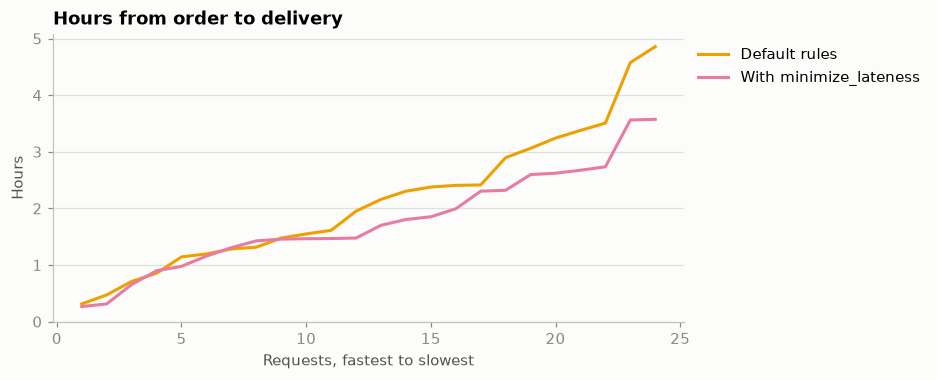

default : mean 2.13 h, slowest 4.86 h, 5.40 h driving, 0 left out
lateness: mean 1.78 h, slowest 3.57 h, 5.66 h driving, 0 left out


In [9]:
order_rng = np.random.default_rng(3)
waited = {order["id"]: int(order_rng.integers(0, 3)) * HOUR for order in orders}

ordered = problem.model_copy(deep=True)
for delivery in ordered.deliveries:
    delivery.order_time = delivery.pickup.min_start_time - waited[delivery.id]


def hours_to_delivery(model_input, solution):
    """Hours from each order to the end of its dropoff, sorted, for the requests that were served."""
    deliveries = {d.id: d for d in model_input.deliveries}
    hours = []
    for route in solution.routes.values():
        for stop in route:
            if not stop.pickup:
                delivery = deliveries[stop.delivery_id]
                done = max(stop.arrival_time, delivery.dropoff.min_start_time) + delivery.dropoff.service_duration
                hours.append((done - delivery.order_time) / HOUR)
    return np.sort(hours)


LATENESS_WEIGHT = 1e-5
with_lateness = [c for c in rules.get_constraints() if c.name != "minimize_lateness"]
with_lateness.append(rules.MinimizeLateness(weight=LATENESS_WEIGHT))

plain = solve_request(PdpRequest(timelimit=4, random_seed=42, model_input=ordered))
prompt = solve_request(PdpRequest(timelimit=4, random_seed=42, model_input=ordered), constraints=with_lateness)

before, after = hours_to_delivery(ordered, plain), hours_to_delivery(ordered, prompt)
fig, ax = plt.subplots(figsize=(7.4, 3.4))
ax.plot(range(1, len(before) + 1), before, color=COLORS[3], linewidth=2, label="Default rules")
ax.plot(range(1, len(after) + 1), after, color=COLORS[4], linewidth=2, label="With minimize_lateness")
ax.set(title="Hours from order to delivery", xlabel="Requests, fastest to slowest", ylabel="Hours", ylim=(0, None))
ax.grid(True, axis="y")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

for label, hours, result in (("default ", before, plain), ("lateness", after, prompt)):
    print(f"{label}: mean {hours.mean():.2f} h, slowest {hours.max():.2f} h, "
          f"{result.total_driving_seconds / HOUR:.2f} h driving, {len(result.unassigned)} left out")

The solver runs for a fixed time, so these numbers are the best found in that time rather than proven
optima. The weight sets how much extra driving a faster order is worth.

## 5. Tighter deadlines

When a promise gets tighter, a van can no longer collect several requests before delivering them. The
hard rules still hold, so the medium level decides what gives: a request off every route costs its
service minutes. Each map below is titled with its deadline, counted from the booking hour, and black
crosses mark both stops of the requests the solver gave up.

Reducing capacity would be a weaker test on this data. A request larger than a van can never be
carried, so what is left out then says more about the input than about the plan.

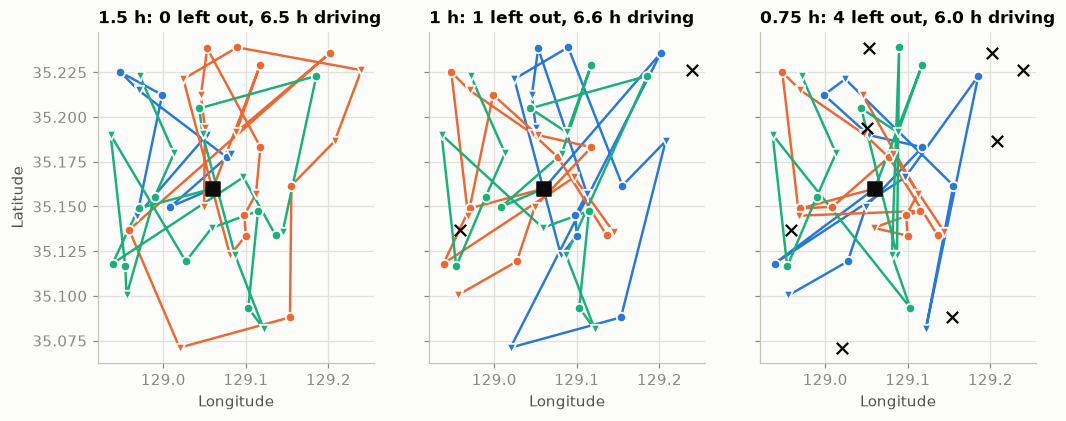

3 h deadline, for comparison: 0 left out, 5.4 h driving


In [10]:
DEADLINES = [1.5, 1.0, 0.75]
fig, axes = plt.subplots(1, 3, figsize=(11, 3.9), sharex=True, sharey=True)
for ax, deadline in zip(axes, DEADLINES):
    tight = make_input(deadline_hours=deadline)
    result = solve_request(PdpRequest(timelimit=3, random_seed=42, model_input=tight))
    draw_routes(ax, tight, result)
    ax.set_title(f"{deadline:g} h: {len(result.unassigned)} left out, "
                 f"{result.total_driving_seconds / HOUR:.1f} h driving", fontsize=11)
axes[1].set_ylabel("")
axes[2].set_ylabel("")
plt.show()
print(f"3 h deadline, for comparison: {len(solution.unassigned)} left out, "
      f"{solution.total_driving_seconds / HOUR:.1f} h driving")

## 6. Keep working from an existing plan

### A late request, with the morning pinned

It is 11:00, the vans are on the road, and a new request comes in. Stops already made cannot change.
`with_initial_solution` turns the solution into each van's `initial_route`, and `pinned_stops` fixes
that many leading stops. The rest of the route stays free: it can be reordered, moved to another van,
or have stops inserted.

Pinning a pickup also keeps its request on that van, because both stops must share a vehicle. A
request in no route, like the new one, is placed by construction and then improved by the search.

In [11]:
NOW = 11 * HOUR

replan = with_initial_solution(request, solution)
replan.timelimit = 3
replan.random_seed = 43
pinned = {}
for vehicle in replan.model_input.vehicles:
    pinned[vehicle.id] = sum(stop.arrival_time < NOW for stop in solution.routes[vehicle.id])
    vehicle.pinned_stops = pinned[vehicle.id]

replan.model_input.deliveries.append(DeliveryModel(
    id="R24",
    demand=3,
    pickup=StopModel(id="R24-P", location=(35.20, 129.11), min_start_time=NOW, max_end_time=13 * HOUR,
                     service_duration=5 * 60),
    dropoff=StopModel(id="R24-D", location=(35.12, 129.02), min_start_time=NOW, max_end_time=14 * HOUR,
                      service_duration=5 * 60),
))

updated = solve_request(replan)

print("score:", updated.score)
print("pinned stops per van:", pinned)
for vehicle in replan.model_input.vehicles:
    count = pinned[vehicle.id]
    kept = [s.stop_id for s in updated.routes[vehicle.id][:count]]
    print(f"{vehicle.id}: pinned stops kept: {kept == vehicle.initial_route[:count]}")
print("new request on:", [van for van, route in updated.routes.items() if any(s.delivery_id == "R24" for s in route)])
print("left out:", updated.unassigned)

score: 0hard/0medium/-20205soft
pinned stops per van: {'Van 1': 4, 'Van 2': 7, 'Van 3': 8}
Van 1: pinned stops kept: True
Van 2: pinned stops kept: True
Van 3: pinned stops kept: True
new request on: ['Van 2']
left out: []


The black rings mark the pinned stops, which stay at the head of each route in both maps. The star and
the plus mark the new pickup and dropoff.

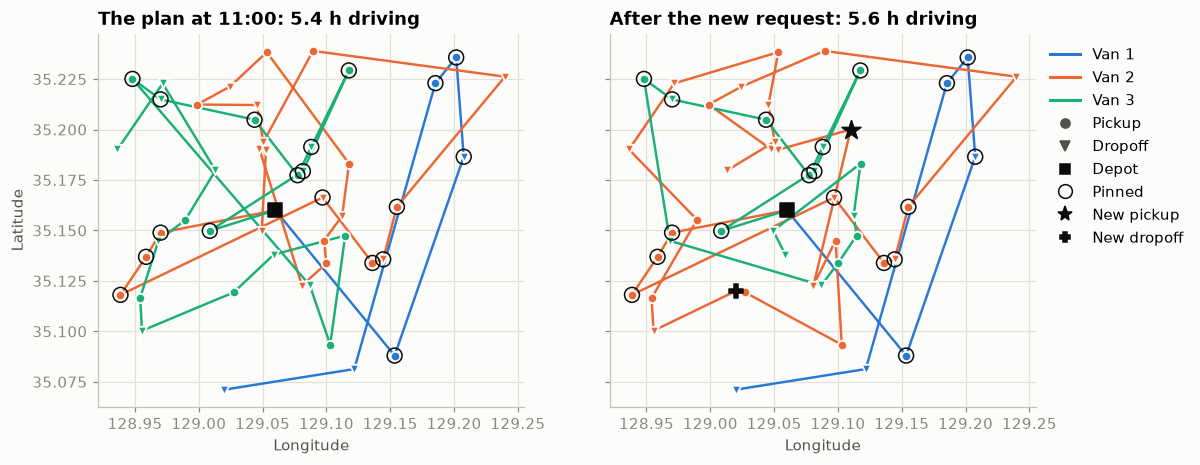

In [12]:
def draw_pins(ax, model_input, solution, pinned):
    where = coordinates(model_input)
    for van, count in pinned.items():
        stops = [where[stop.stop_id] for stop in solution.routes[van][:count]]
        ax.scatter([p[1] for p in stops], [p[0] for p in stops], s=95, facecolor="none", edgecolor="#0b0b0b",
                   linewidth=1, zorder=4)


new_stops = replan.model_input.deliveries[-1]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharex=True, sharey=True)
for ax, model_input, result, title in (
    (axes[0], problem, solution, "The plan at 11:00"),
    (axes[1], replan.model_input, updated, "After the new request"),
):
    draw_routes(ax, model_input, result)
    draw_pins(ax, model_input, result, pinned)
    ax.set_title(f"{title}: {result.total_driving_seconds / HOUR:.1f} h driving")
axes[1].scatter(new_stops.pickup.location[1], new_stops.pickup.location[0], marker="*", s=170,
                color="#0b0b0b", zorder=5)
axes[1].scatter(new_stops.dropoff.location[1], new_stops.dropoff.location[0], marker="P", s=80,
                color="#0b0b0b", zorder=5)
axes[1].set_ylabel("")
route_legend(axes[1], problem, extra=[
    Line2D([], [], linestyle="", marker="o", markerfacecolor="none", markeredgecolor="#0b0b0b", markersize=9,
           label="Pinned"),
    Line2D([], [], linestyle="", marker="*", color="#0b0b0b", markersize=10, label="New pickup"),
    Line2D([], [], linestyle="", marker="P", color="#0b0b0b", markersize=7, label="New dropoff"),
])
plt.show()

### More search, in rounds

`with_initial_solution` also lets you spend more time on a result, in rounds that each continue from
the last answer.

**Give each round its own `random_seed`.** The same start with the same seed repeats the same search,
so that round has nothing new to find. The chart runs both from one starting solution. A same-seed run can still improve for a while,
because each better answer is a new start. The first round that finds nothing ends it: the next round
has the same start and the same seed.

A round reports the best solution it saw, and its start counts, so a round that finds nothing better
hands back its start unchanged. Steps in the line are normal. If the line stays flat for many rounds
with changing seeds, look at why before trusting it: try longer rounds, and compare against a single
solve of the same total length, as the horizontal line does here.

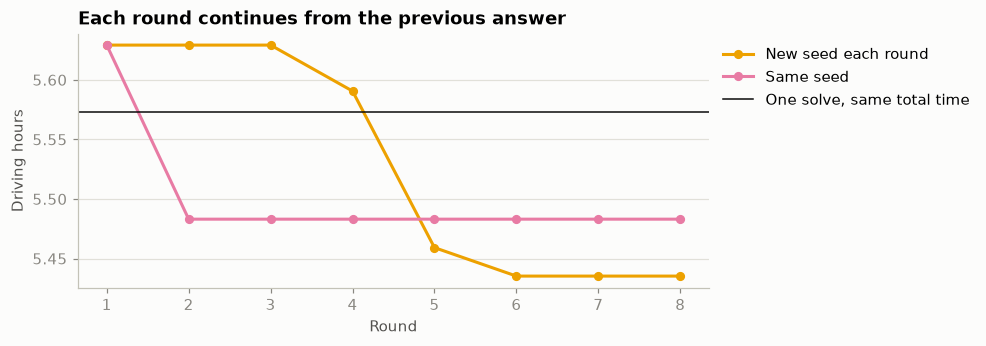

rounds that changed the routes: new seed 3 of 7, same seed 1 of 7
best driving: new seed 5.44 h, same seed 5.48 h, one solve 5.57 h


In [13]:
ROUNDS = 8
ROUND_SECONDS = 0.3


def driving_hours(result):
    return result.total_driving_seconds / HOUR


def search_in_rounds(start, change_seed):
    history, changed, current = [driving_hours(start)], 0, start
    next_request = PdpRequest(timelimit=ROUND_SECONDS, random_seed=100, model_input=problem)
    for round_number in range(1, ROUNDS):
        next_request = with_initial_solution(next_request, current)
        if change_seed:
            next_request.random_seed = 100 + round_number
        result = solve_request(next_request)
        changed += result.routes != current.routes
        current = result
        history.append(driving_hours(current))
    return history, changed


start = solve_request(PdpRequest(timelimit=ROUND_SECONDS, random_seed=100, model_input=problem))
new_seed, new_seed_changes = search_in_rounds(start, change_seed=True)
same_seed, same_seed_changes = search_in_rounds(start, change_seed=False)
one_solve = solve_request(PdpRequest(timelimit=ROUNDS * ROUND_SECONDS, random_seed=100, model_input=problem))

fig, ax = plt.subplots(figsize=(7.4, 3))
rounds = range(1, ROUNDS + 1)
ax.plot(rounds, new_seed, color=COLORS[3], linewidth=2, marker="o", markersize=5, label="New seed each round")
ax.plot(rounds, same_seed, color=COLORS[4], linewidth=2, marker="o", markersize=5, label="Same seed")
ax.axhline(driving_hours(one_solve), color="#0b0b0b", linewidth=1, label="One solve, same total time")
ax.set(title="Each round continues from the previous answer", xlabel="Round", ylabel="Driving hours")
ax.grid(True, axis="y")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

print(f"rounds that changed the routes: new seed {new_seed_changes} of {ROUNDS - 1}, "
      f"same seed {same_seed_changes} of {ROUNDS - 1}")
print(f"best driving: new seed {new_seed[-1]:.2f} h, same seed {same_seed[-1]:.2f} h, "
      f"one solve {driving_hours(one_solve):.2f} h")

## Next steps

- `required_vehicle` on a request keeps it on one van without fixing its place on the route. `VehicleModel`
  also takes `max_travel_time`, `max_route_duration`, `max_end_time`, `min_load_ratio`, `fixed_cost` and
  `max_route_radius_meters`.
- `use-cases/pickup-delivery/README.md` covers the main constraints, the pair-aware moves, and how to
  add your own moves and constraints in C++.
- For deliveries that all start from a depot, with no pickup pairs, see `vehicle-routing.ipynb`.